In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv("../data/opsd_germany_daily.csv")
df["Date"] = pd.to_datetime(df["Date"], format='%Y-%m-%d')

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month_name()
df['Weekday'] = df['Date'].dt.day_name()

df.insert(1, 'Year', df.pop('Year'))
df.insert(2, 'Month', df.pop('Month'))
df.insert(3, 'Weekday', df.pop('Weekday'))
df = df.set_index("Date")
df = df.sort_index()

In [10]:
print(df.index)
print(df.index.dtype)

DatetimeIndex(['2006-01-01', '2006-01-02', '2006-01-03', '2006-01-04',
               '2006-01-05', '2006-01-06', '2006-01-07', '2006-01-08',
               '2006-01-09', '2006-01-10',
               ...
               '2017-12-22', '2017-12-23', '2017-12-24', '2017-12-25',
               '2017-12-26', '2017-12-27', '2017-12-28', '2017-12-29',
               '2017-12-30', '2017-12-31'],
              dtype='datetime64[us]', name='Date', length=4383, freq=None)
datetime64[us]


In [11]:
df.columns # dtype='str'

Index(['Year', 'Month', 'Weekday', 'Consumption', 'Wind', 'Solar',
       'Wind+Solar'],
      dtype='str')

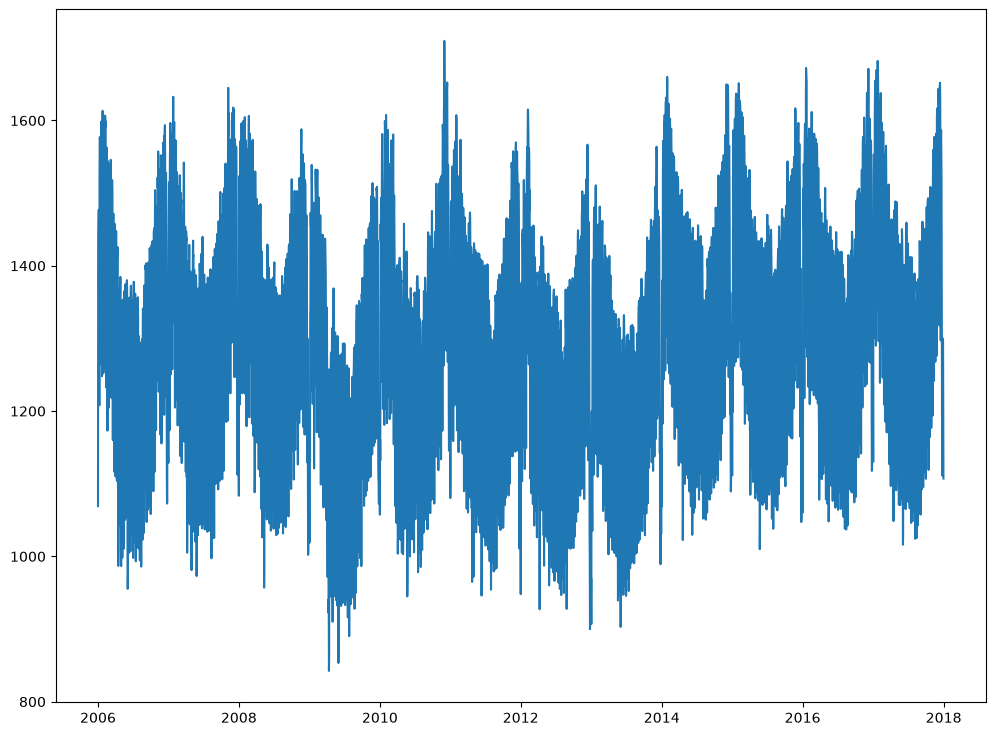

In [12]:
# EX.19

plt.figure(figsize=(12,9))

plt.plot(df.index, df["Consumption"])

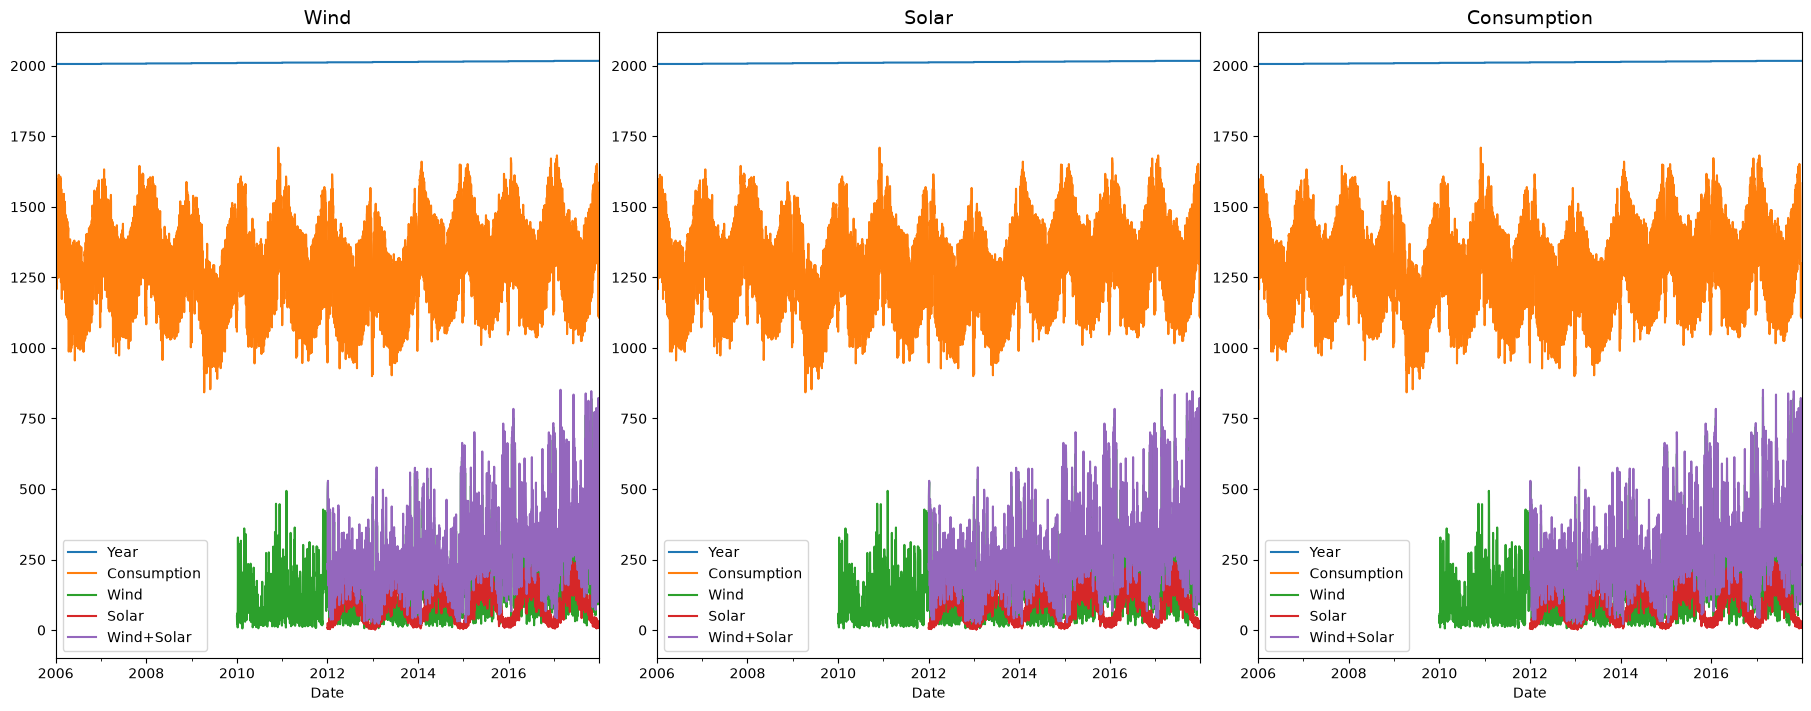

In [13]:
#EX.20

energy_types = ['Wind', 'Solar', 'Consumption']

fig, axes = plt.subplots(1, 3, figsize=(18, 7), constrained_layout=True, sharey=False)

for ax, type in zip(axes, energy_types):
    df.plot(
        ax=ax,
        column=energy_types,
    )
    ax.set_title(type, fontsize=14)

<Axes: xlabel='Date'>

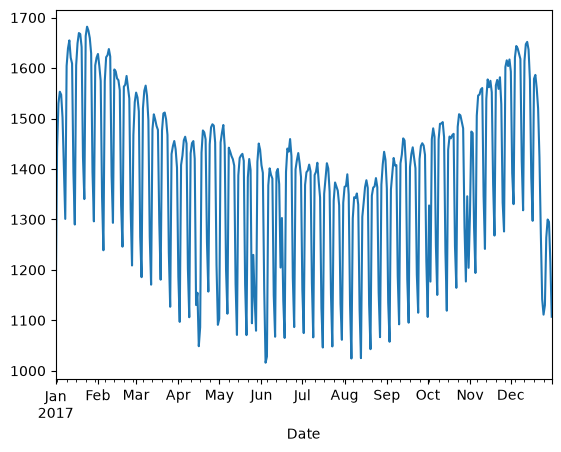

In [14]:
# EX.21

# Daily observations
cons_2017 = df.loc['2017', 'Consumption']

cons_2017.plot() 

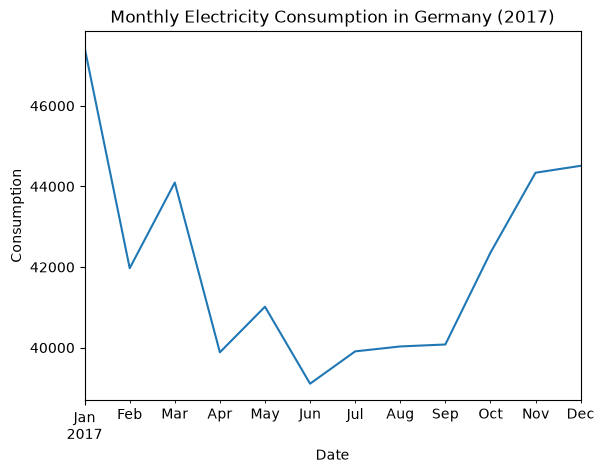

In [15]:
# Monthly observations

consumption_2017_monthly = df.loc['2017', 'Consumption'].resample('ME').sum()
consumption_2017_monthly.plot()

plt.title('Monthly Electricity Consumption in Germany (2017)')
plt.xlabel('Date')
plt.ylabel('Consumption')

plt.show()


<Axes: xlabel='Date'>

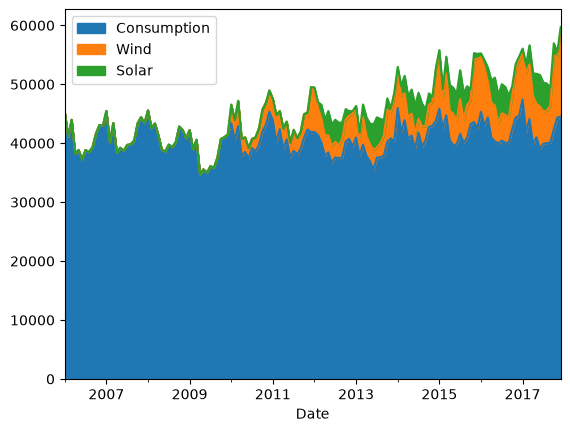

In [16]:
# EX.22

monthly_data = df[['Consumption', 'Wind', 'Solar']].resample('ME').sum()

# 'line', 'bar', 'barh', 'kde', 'density', 'area', 'hist', 'box', 'pie', 'scatter', 'hexbin'
monthly_data.plot(kind="area")

<Axes: >

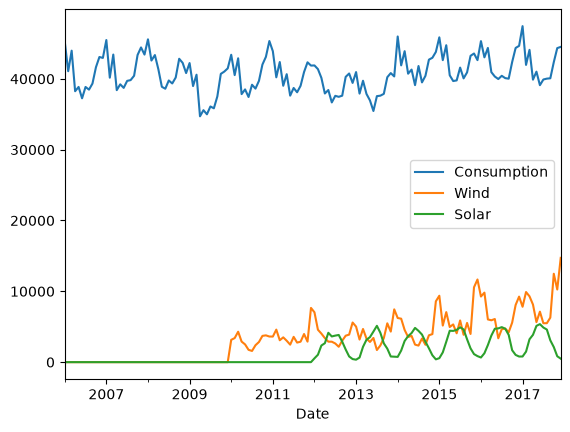

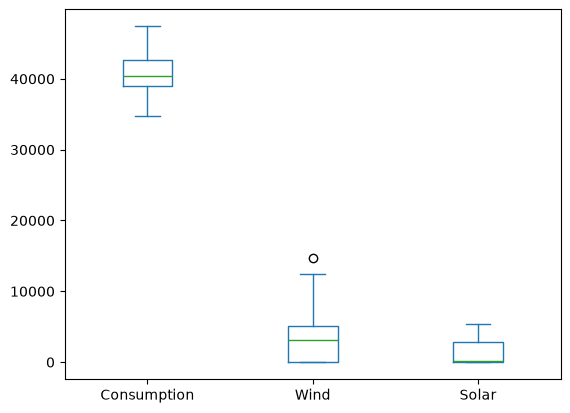

In [17]:
monthly_data.plot(kind="line")
monthly_data.plot(kind="box")

In [27]:
# EX.23
vac_df = pd.read_csv("../data/vaccine_data.csv")

In [28]:
vac_df["Date"] = pd.to_datetime(vac_df["Date"], format='%Y-%m-%d')
vac_df = vac_df.set_index("Date")

vac_df.head()

,Vaccine
Date,
2015-07-01,1555
2015-07-02,1514
2015-07-03,1233
2015-07-04,1067
2015-07-05,1190


In [29]:
vac_df.isna().sum()

Vaccine    0
dtype: int64

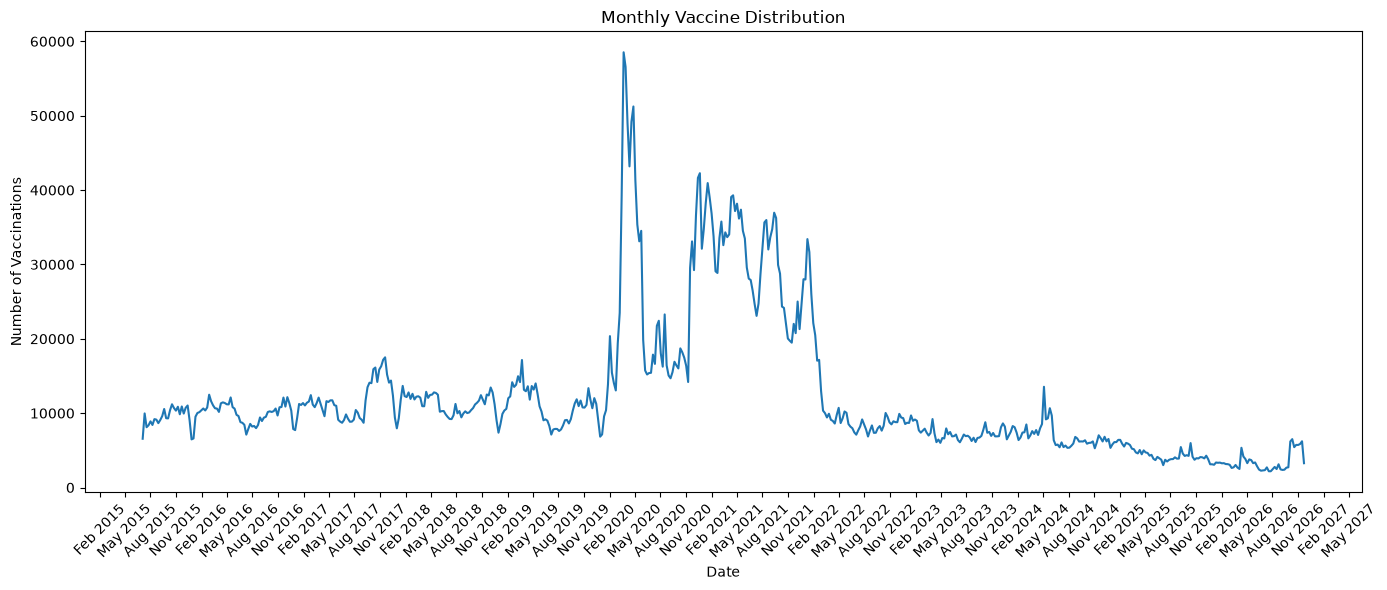

In [44]:
import matplotlib.dates as mdates

vac_df_monthly = vac_df["Vaccine"].resample('W').sum()

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(vac_df_monthly.index, vac_df_monthly.values)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))

ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xticks(rotation=45)

plt.title('Monthly Vaccine Distribution')
plt.xlabel('Date')
plt.ylabel('Number of Vaccinations')

plt.tight_layout()
plt.show()
